In [1]:

!pip install -q evidently


In [2]:
# import libraries


import pandas as pd
import numpy as np
import os

from evidently import Report
from evidently.presets import DataDriftPreset

from google.colab import drive
from IPython.display import display


In [3]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

# Load the database

drive.mount('/content/drive')

file_path = DATA_DIR / "retail_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Mounted at /content/drive
Dataset shape: (410763, 10)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'IsCancelled', 'Revenue']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [4]:
# Prepare daily retail demand


df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df = df.dropna(
    subset=["InvoiceDate", "StockCode", "Quantity"]
).copy()

if "IsCancelled" in df.columns:
    df = df[df["IsCancelled"] == 0].copy()

df = df[df["Quantity"] > 0].copy()

df["Date"] = df["InvoiceDate"].dt.floor("D")

daily = (
    df.groupby(["Date", "StockCode"], as_index=False)
      .agg(
          DailyDemand=("Quantity", "sum"),
          Revenue=("Revenue", "sum")
          if "Revenue" in df.columns
          else ("Quantity", "sum")
      )
)

print("Daily product records:", daily.shape)
display(daily.head())
#

Daily product records: (223833, 4)


,Date,StockCode,DailyDemand,Revenue
0,2009-12-01,10002,12,10.20
1,2009-12-01,10120,60,12.60
2,2009-12-01,10125,4,3.40
3,2009-12-01,10133,6,5.10
4,2009-12-01,10135,17,21.25


In [5]:
# Select a product and create drift features


selected_product = (
    daily.groupby("StockCode")["DailyDemand"]
         .sum()
         .idxmax()
)

product_df = (
    daily[daily["StockCode"] == selected_product]
    .sort_values("Date")
    .set_index("Date")
    .asfreq("D")
)

product_df["StockCode"] = str(selected_product)

# Fill days without sales with zero demand.
product_df["DailyDemand"] = (
    product_df["DailyDemand"].fillna(0)
)

product_df["Revenue"] = product_df["Revenue"].fillna(0)

# Calendar features
product_df["DayOfWeek"] = product_df.index.dayofweek
product_df["Month"] = product_df.index.month
product_df["DayOfMonth"] = product_df.index.day

# Lag and rolling features
product_df["Lag_1"] = product_df["DailyDemand"].shift(1)
product_df["Lag_7"] = product_df["DailyDemand"].shift(7)

product_df["RollingMean_7"] = (
    product_df["DailyDemand"].shift(1).rolling(7).mean()
)

product_df["RollingStd_7"] = (
    product_df["DailyDemand"].shift(1).rolling(7).std()
)

product_df = product_df.dropna().reset_index()

print("Selected product:", selected_product)
print("Prepared data shape:", product_df.shape)
display(product_df.head())


Selected product: 21212
Prepared data shape: (367, 11)


,Date,StockCode,DailyDemand,Revenue,DayOfWeek,Month,DayOfMonth,Lag_1,Lag_7,RollingMean_7,RollingStd_7
0,2009-12-08,21212,97.0,53.35,1,12,8,72.0,294.0,219.714286,176.293991
1,2009-12-09,21212,192.0,90.00,2,12,9,97.0,574.0,191.571429,178.173003
2,2009-12-10,21212,303.0,151.05,3,12,10,192.0,182.0,137.000000,62.417946
3,2009-12-11,21212,304.0,136.00,4,12,11,303.0,193.0,154.285714,88.332165
4,2009-12-12,21212,0.0,0.00,5,12,12,304.0,48.0,170.142857,104.857727


In [6]:
# Create reference and current datasets


product_df = product_df.sort_values("Date").reset_index(drop=True)

if len(product_df) <= 60:
    raise ValueError(
        "Not enough daily records. Use a longer history "
        "or a smaller current monitoring window."
    )

current_days = 30

reference_df = product_df.iloc[:-current_days].copy()
current_df = product_df.iloc[-current_days:].copy()

# Do not include the date or product identifier in this
# initial feature-distribution report.
drift_columns = [
    "DailyDemand",
    "Revenue",
    "DayOfWeek",
    "Month",
    "DayOfMonth",
    "Lag_1",
    "Lag_7",
    "RollingMean_7",
    "RollingStd_7"
]

reference_data = reference_df[drift_columns].copy()
current_data = current_df[drift_columns].copy()

print("Reference date range:",
      reference_df["Date"].min(),
      "to", reference_df["Date"].max())

print("Current date range:",
      current_df["Date"].min(),
      "to", current_df["Date"].max())

print("Reference rows:", len(reference_data))
print("Current rows:", len(current_data))


Reference date range: 2009-12-08 00:00:00 to 2010-11-09 00:00:00
Current date range: 2010-11-10 00:00:00 to 2010-12-09 00:00:00
Reference rows: 337
Current rows: 30


In [7]:
# Run Evidently drift detection


drift_report = Report([
    DataDriftPreset()
])

drift_results = drift_report.run(
    current_data=current_data,
    reference_data=reference_data
)

drift_results


Output hidden; open in https://colab.research.google.com to view.

In [8]:
# Save the HTML report


output_dir = str(PROJECT_DIR / "drift_outputs")

os.makedirs(output_dir, exist_ok=True)

report_path = os.path.join(
    output_dir,
    "retailpulse_data_drift_report.html"
)

drift_results.save_html(report_path)

print("Drift report saved to:")
print(report_path)


Drift report saved to:
/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/drift_outputs/retailpulse_data_drift_report.html


In [9]:
# Compare summary statistics


comparison = pd.DataFrame({
    "Reference Mean": reference_data.mean(numeric_only=True),
    "Current Mean": current_data.mean(numeric_only=True),
    "Reference Std": reference_data.std(numeric_only=True),
    "Current Std": current_data.std(numeric_only=True)
})

comparison["Mean Change (%)"] = (
    (comparison["Current Mean"] - comparison["Reference Mean"])
    / comparison["Reference Mean"].replace(0, np.nan)
    * 100
)

display(comparison.round(2))


,Reference Mean,Current Mean,Reference Std,Current Std,Mean Change (%)
DailyDemand,150.32,176.97,180.81,223.91,17.73
Revenue,72.33,82.63,80.17,97.36,14.24
DayOfWeek,2.99,2.97,2.00,1.97,-0.92
Month,6.13,11.30,3.30,0.47,84.23
DayOfMonth,15.70,15.50,8.81,8.80,-1.26
Lag_1,150.07,180.00,180.86,222.96,19.94
Lag_7,152.54,181.80,182.33,222.09,19.18
RollingMean_7,150.72,181.54,69.95,53.30,20.45
RollingStd_7,159.10,205.36,85.04,104.78,29.07


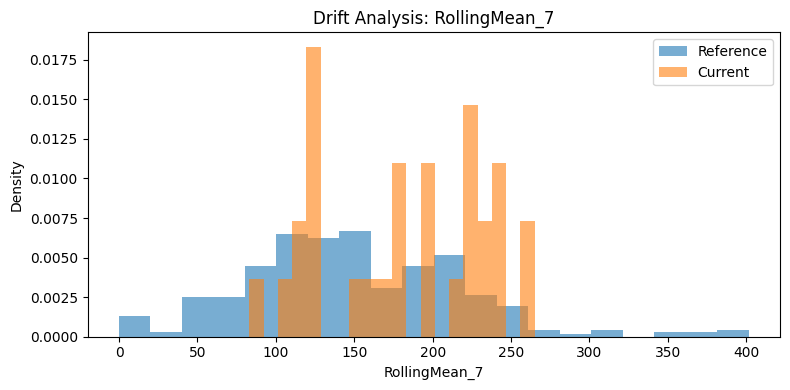

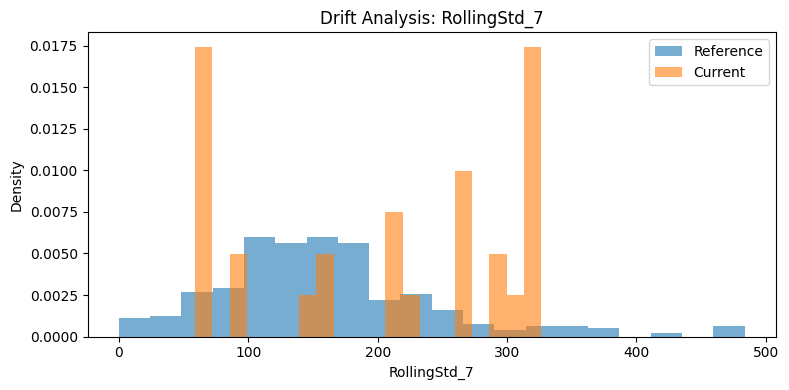

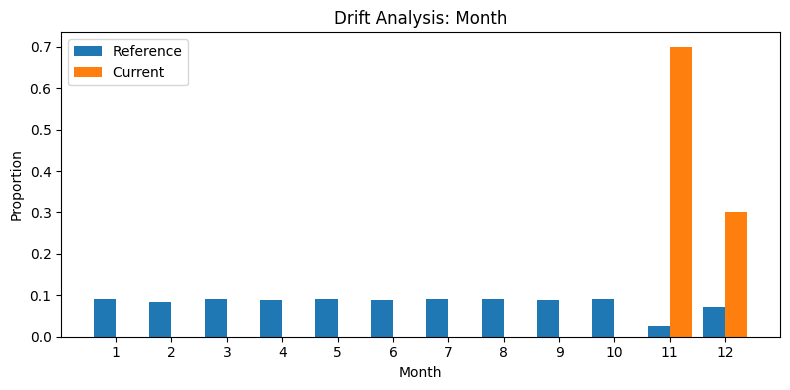

In [11]:
# inspect the drifted features
import matplotlib.pyplot as plt

drifted_features = [
    "RollingMean_7",
    "RollingStd_7",
    "Month"
]

for feature in drifted_features:
    plt.figure(figsize=(8, 4))

    if feature == "Month":
        months = range(1, 13)

        reference_counts = (
            reference_data["Month"]
            .value_counts(normalize=True)
            .reindex(months, fill_value=0)
        )

        current_counts = (
            current_data["Month"]
            .value_counts(normalize=True)
            .reindex(months, fill_value=0)
        )

        width = 0.4
        plt.bar(
            [m - width / 2 for m in months],
            reference_counts.values,
            width=width,
            label="Reference"
        )
        plt.bar(
            [m + width / 2 for m in months],
            current_counts.values,
            width=width,
            label="Current"
        )
        plt.xticks(list(months))
        plt.ylabel("Proportion")
    else:
        plt.hist(
            reference_data[feature],
            bins=20,
            alpha=0.6,
            density=True,
            label="Reference"
        )
        plt.hist(
            current_data[feature],
            bins=20,
            alpha=0.6,
            density=True,
            label="Current"
        )
        plt.ylabel("Density")

    plt.title(f"Drift Analysis: {feature}")
    plt.xlabel(feature)
    plt.legend()
    plt.tight_layout()
    plt.show()


# Key Insights

Evidently detected changes in the recent rolling demand statistics and month distribution, but the percentage of drifted columns remained below the dataset-level threshold. The appropriate next step is to investigate these changes and validate whether they affect forecasting accuracy before retraining the model.